In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

# Define project directories
BASE_DIR = Path("..")
DATA_DIR = BASE_DIR / "data"
PROCESSED_DIR = DATA_DIR / "processed"
RESULTS_DIR = DATA_DIR / "results"

# Load NLP features
nlp_features = pd.read_csv(
    PROCESSED_DIR / "integrated_nlp_features.csv"
)

# Load quantitative event data
pilot_events = pd.read_csv(
    RESULTS_DIR / "pilot_events.csv"
)

# Inspect datasets
print("NLP Dataset Shape:", nlp_features.shape)
print("Pilot Events Shape:", pilot_events.shape)

print("\nNLP Dataset Columns:")
print(nlp_features.columns.tolist())

print("\nPilot Events Columns:")
print(pilot_events.columns.tolist())

print("\nNLP Dataset Sample:")
display(nlp_features.head(3))

print("\nPilot Events Sample:")
display(pilot_events.head(3))

NLP Dataset Shape: (50, 13)
Pilot Events Shape: (8, 11)

NLP Dataset Columns:
['Headline', 'FinBERT_Sentiment', 'FinBERT_Confidence', 'Positive_Probability', 'Negative_Probability', 'Neutral_Probability', 'Sentiment_Entropy', 'NER_Entities', 'NER_Entity_Labels', 'NER_Entity_Count', 'BERTopic_ID', 'BERTopic_Name', 'Topic_Probability']

Pilot Events Columns:
['event_id', 'company', 'event_date', 'event_category', 'headline', 'source', 'source_url', 'reaction_date', 'available_estimation_days', 'announcement_timing', 'verification_status']

NLP Dataset Sample:


,Headline,FinBERT_Sentiment,FinBERT_Confidence,Positive_Probability,Negative_Probability,Neutral_Probability,Sentiment_Entropy,NER_Entities,NER_Entity_Labels,NER_Entity_Count,BERTopic_ID,BERTopic_Name,Topic_Probability
0,Nikkei 225 index benefits from a weaker yen,negative,0.845792,0.134032,0.845792,0.020176,0.445805,NaN,NaN,0,1,1_report_earnings_retail_manufacturing,1.0
1,Government subsidy program gives a lift to the...,positive,0.917761,0.917761,0.019526,0.062713,0.299722,NaN,NaN,0,-1,-1_central_government_bank_banks,0.0
2,New housing data release shows a slowdown in m...,negative,0.970689,0.009306,0.970689,0.020006,0.137135,NaN,NaN,0,0,0_market_as_investors_shows,1.0



Pilot Events Sample:


,event_id,company,event_date,event_category,headline,source,source_url,reaction_date,available_estimation_days,announcement_timing,verification_status
0,EV001,AAPL,2025-01-30,Quarterly Earnings,Apple reports first quarter results,Apple IR,https://www.apple.com/newsroom/2025/01/apple-r...,2025-01-31,100,After market close,Official source verified
1,EV002,AAPL,2025-05-01,Quarterly Earnings,Apple reports second quarter results,Apple IR,https://www.apple.com/newsroom/2025/05/apple-r...,2025-05-02,100,After market close,Official source verified
2,EV003,AAPL,2025-07-31,Quarterly Earnings,Apple reports third quarter results,Apple IR,https://www.apple.com/in/newsroom/2025/07/appl...,2025-08-01,100,After market close,Official source verified


In [2]:
# Load event-level CAR summary
car_summary = pd.read_csv(
    RESULTS_DIR / "event_car_summary.csv"
)

print("CAR Summary Shape:", car_summary.shape)

print("\nAvailable Columns:")
print(car_summary.columns.tolist())

display(car_summary)

CAR Summary Shape: (8, 6)

Available Columns:
['event_id', 'company', 'total_CAR', 'average_AR', 'max_CAR', 'min_CAR']


,event_id,company,total_CAR,average_AR,max_CAR,min_CAR
0,EV001,AAPL,-0.737394,-0.035114,-0.737394,-8.933771
1,EV002,AAPL,-1.784097,-0.084957,4.311323,-4.587054
2,EV003,AAPL,9.054650,0.431174,9.222825,-2.652831
3,EV004,MSFT,-4.579524,-0.218073,3.906962,-4.579524
4,EV005,MSFT,7.915669,0.376937,8.992909,-2.697776
5,EV006,MSFT,-2.964244,-0.141154,2.796384,-3.139331
6,EV007,TSLA,-18.695251,-0.890250,0.000021,-18.695251
7,EV008,TSLA,7.695698,0.366462,10.589217,0.662464


In [3]:
# Create an event-news mapping template
event_news_mapping = pilot_events[
    [
        "event_id",
        "company",
        "event_date",
        "event_category",
        "headline",
        "source",
        "source_url",
        "reaction_date"
    ]
].copy()

# Add fields for future verified news data
event_news_mapping["news_headline"] = ""
event_news_mapping["news_source"] = ""
event_news_mapping["news_url"] = ""
event_news_mapping["news_publication_date"] = ""
event_news_mapping["news_verification_status"] = "Pending"

# Save template
event_news_mapping.to_csv(
    RESULTS_DIR / "event_news_mapping_template.csv",
    index=False
)

print("Event-news mapping template created!")
print("Shape:", event_news_mapping.shape)

display(event_news_mapping)

Event-news mapping template created!
Shape: (8, 13)


,event_id,company,event_date,event_category,headline,source,source_url,reaction_date,news_headline,news_source,news_url,news_publication_date,news_verification_status
0,EV001,AAPL,2025-01-30,Quarterly Earnings,Apple reports first quarter results,Apple IR,https://www.apple.com/newsroom/2025/01/apple-r...,2025-01-31,,,,,Pending
1,EV002,AAPL,2025-05-01,Quarterly Earnings,Apple reports second quarter results,Apple IR,https://www.apple.com/newsroom/2025/05/apple-r...,2025-05-02,,,,,Pending
2,EV003,AAPL,2025-07-31,Quarterly Earnings,Apple reports third quarter results,Apple IR,https://www.apple.com/in/newsroom/2025/07/appl...,2025-08-01,,,,,Pending
3,EV004,MSFT,2025-01-29,Quarterly Earnings,Microsoft FY2025 Q2 earnings,Microsoft IR,https://www.microsoft.com/en-us/investor/earni...,2025-01-30,,,,,Pending
4,EV005,MSFT,2025-04-30,Quarterly Earnings,Microsoft FY2025 Q3 earnings,Microsoft IR,https://www.microsoft.com/en-us/investor/earni...,2025-05-01,,,,,Pending
5,EV006,MSFT,2025-07-30,Quarterly Earnings,Microsoft FY2025 Q4 earnings,Microsoft IR,https://www.microsoft.com/en-us/investor/earni...,2025-07-31,,,,,Pending
6,EV007,TSLA,2025-04-22,Quarterly Earnings,Tesla Q1 2025 earnings,Tesla IR,https://ir.tesla.com/press-release/tesla-relea...,2025-04-23,,,,,Pending
7,EV008,TSLA,2025-07-23,Quarterly Earnings,Tesla Q2 2025 earnings,Tesla IR,https://ir.tesla.com/press-release/tesla-relea...,2025-07-24,,,,,Pending


In [4]:
# Official announcement details
verified_news = {
    "EV001": {
        "title": "Apple reports first quarter results",
        "date": "2025-01-30",
        "url": "https://www.apple.com/newsroom/2025/01/apple-reports-first-quarter-results/"
    },
    "EV002": {
        "title": "Apple reports second quarter results",
        "date": "2025-05-01",
        "url": "https://www.apple.com/newsroom/2025/05/apple-reports-second-quarter-results/"
    },
    "EV003": {
        "title": "Apple reports third quarter results",
        "date": "2025-07-31",
        "url": "https://www.apple.com/in/newsroom/2025/07/apple-reports-third-quarter-results/"
    },
    "EV004": {
        "title": "Microsoft Cloud and AI Strength Drives Second Quarter Results",
        "date": "2025-01-29",
        "url": "https://www.microsoft.com/en-us/investor/earnings/fy-2025-q2/press-release-webcast"
    },
    "EV005": {
        "title": "Microsoft Cloud and AI Strength Drives Third Quarter Results",
        "date": "2025-04-30",
        "url": "https://www.microsoft.com/en-us/investor/earnings/fy-2025-q3/press-release-webcast"
    },
    "EV006": {
        "title": "Microsoft Cloud and AI Strength Fuels Fourth Quarter Results",
        "date": "2025-07-30",
        "url": "https://www.microsoft.com/en-us/investor/earnings/fy-2025-q4/press-release-webcast"
    },
    "EV007": {
        "title": "Tesla Releases First Quarter 2025 Financial Results",
        "date": "2025-04-22",
        "url": "https://ir.tesla.com/press-release/tesla-releases-first-quarter-2025-financial-results"
    },
    "EV008": {
        "title": "Tesla Releases Second Quarter 2025 Financial Results",
        "date": "2025-07-23",
        "url": "https://ir.tesla.com/press-release/tesla-releases-second-quarter-2025-financial-results"
    }
}

# Populate the mapping table
for event_id, details in verified_news.items():
    mask = event_news_mapping["event_id"] == event_id

    event_news_mapping.loc[mask, "news_headline"] = details["title"]
    event_news_mapping.loc[mask, "news_source"] = (
        event_news_mapping.loc[mask, "source"]
    )
    event_news_mapping.loc[mask, "news_url"] = details["url"]
    event_news_mapping.loc[mask, "news_publication_date"] = details["date"]
    event_news_mapping.loc[mask, "news_verification_status"] = (
        "Official announcement title and date verified"
    )

# Save updated mapping
event_news_mapping.to_csv(
    RESULTS_DIR / "event_news_mapping_template.csv",
    index=False
)

print("Official announcement mapping updated!")
display(
    event_news_mapping[
        ["event_id", "company", "news_headline",
         "news_publication_date", "news_verification_status"]
    ]
)

Official announcement mapping updated!


,event_id,company,news_headline,news_publication_date,news_verification_status
0,EV001,AAPL,Apple reports first quarter results,2025-01-30,Official announcement title and date verified
1,EV002,AAPL,Apple reports second quarter results,2025-05-01,Official announcement title and date verified
2,EV003,AAPL,Apple reports third quarter results,2025-07-31,Official announcement title and date verified
3,EV004,MSFT,Microsoft Cloud and AI Strength Drives Second ...,2025-01-29,Official announcement title and date verified
4,EV005,MSFT,Microsoft Cloud and AI Strength Drives Third Q...,2025-04-30,Official announcement title and date verified
5,EV006,MSFT,Microsoft Cloud and AI Strength Fuels Fourth Q...,2025-07-30,Official announcement title and date verified
6,EV007,TSLA,Tesla Releases First Quarter 2025 Financial Re...,2025-04-22,Official announcement title and date verified
7,EV008,TSLA,Tesla Releases Second Quarter 2025 Financial R...,2025-07-23,Official announcement title and date verified


In [7]:
from transformers import pipeline

# Load pretrained FinBERT model
finbert = pipeline(
    "sentiment-analysis",
    model="ProsusAI/finbert",
    tokenizer="ProsusAI/finbert",
    device=-1
)

print("FinBERT model loaded successfully!")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

FinBERT model loaded successfully!


In [8]:
# Extract verified announcement headlines
event_headlines = event_news_mapping["news_headline"].tolist()

# Run FinBERT
event_sentiment_results = finbert(
    event_headlines,
    batch_size=8
)

# Store predictions
event_news_mapping["FinBERT_Sentiment"] = [
    result["label"] for result in event_sentiment_results
]

event_news_mapping["FinBERT_Confidence"] = [
    result["score"] for result in event_sentiment_results
]

# Display results
display(
    event_news_mapping[
        [
            "event_id",
            "company",
            "news_headline",
            "FinBERT_Sentiment",
            "FinBERT_Confidence"
        ]
    ]
)

,event_id,company,news_headline,FinBERT_Sentiment,FinBERT_Confidence
0,EV001,AAPL,Apple reports first quarter results,neutral,0.895360
1,EV002,AAPL,Apple reports second quarter results,neutral,0.822692
2,EV003,AAPL,Apple reports third quarter results,neutral,0.848979
3,EV004,MSFT,Microsoft Cloud and AI Strength Drives Second ...,positive,0.552653
4,EV005,MSFT,Microsoft Cloud and AI Strength Drives Third Q...,positive,0.570248
5,EV006,MSFT,Microsoft Cloud and AI Strength Fuels Fourth Q...,negative,0.780890
6,EV007,TSLA,Tesla Releases First Quarter 2025 Financial Re...,neutral,0.907554
7,EV008,TSLA,Tesla Releases Second Quarter 2025 Financial R...,neutral,0.898837


In [9]:
# Get probabilities for all three sentiment classes
event_all_scores = finbert(
    event_news_mapping["news_headline"].tolist(),
    batch_size=8,
    top_k=None
)

# Extract probabilities
event_probability_df = pd.DataFrame([
    {item["label"]: item["score"] for item in result}
    for result in event_all_scores
])

# Add probabilities to mapping
event_news_mapping["Positive_Probability"] = (
    event_probability_df["positive"].values
)

event_news_mapping["Negative_Probability"] = (
    event_probability_df["negative"].values
)

event_news_mapping["Neutral_Probability"] = (
    event_probability_df["neutral"].values
)

display(
    event_news_mapping[
        [
            "event_id",
            "company",
            "FinBERT_Sentiment",
            "Positive_Probability",
            "Negative_Probability",
            "Neutral_Probability"
        ]
    ]
)

,event_id,company,FinBERT_Sentiment,Positive_Probability,Negative_Probability,Neutral_Probability
0,EV001,AAPL,neutral,0.036920,0.067720,0.895360
1,EV002,AAPL,neutral,0.033113,0.144195,0.822692
2,EV003,AAPL,neutral,0.034501,0.116520,0.848979
3,EV004,MSFT,positive,0.552653,0.265521,0.181826
4,EV005,MSFT,positive,0.570248,0.252987,0.176765
5,EV006,MSFT,negative,0.133448,0.780890,0.085662
6,EV007,TSLA,neutral,0.021508,0.070939,0.907554
7,EV008,TSLA,neutral,0.022726,0.078437,0.898837


In [10]:
# Calculate sentiment entropy
probabilities = event_news_mapping[
    [
        "Positive_Probability",
        "Negative_Probability",
        "Neutral_Probability"
    ]
].values

entropy = -np.sum(
    probabilities * np.log(probabilities + 1e-12),
    axis=1
)

# Normalize entropy between 0 and 1
event_news_mapping["Sentiment_Entropy"] = (
    entropy / np.log(3)
)

# Validate probability sums
event_news_mapping["Probability_Sum"] = (
    event_news_mapping[
        [
            "Positive_Probability",
            "Negative_Probability",
            "Neutral_Probability"
        ]
    ].sum(axis=1)
)

display(
    event_news_mapping[
        [
            "event_id",
            "FinBERT_Sentiment",
            "FinBERT_Confidence",
            "Sentiment_Entropy",
            "Probability_Sum"
        ]
    ]
)

,event_id,FinBERT_Sentiment,FinBERT_Confidence,Sentiment_Entropy,Probability_Sum
0,EV001,neutral,0.895360,0.366908,1.0
1,EV002,neutral,0.822692,0.503051,1.0
2,EV003,neutral,0.848979,0.460248,1.0
3,EV004,positive,0.552653,0.900950,1.0
4,EV005,positive,0.570248,0.886874,1.0
5,EV006,negative,0.780890,0.612046,1.0
6,EV007,neutral,0.907554,0.326148,1.0
7,EV008,neutral,0.898837,0.347277,1.0


In [11]:
# Select relevant sentiment features
sentiment_features = event_news_mapping[
    [
        "event_id",
        "company",
        "FinBERT_Sentiment",
        "FinBERT_Confidence",
        "Positive_Probability",
        "Negative_Probability",
        "Neutral_Probability",
        "Sentiment_Entropy"
    ]
].copy()

# Merge sentiment with CAR results
integrated_event_data = sentiment_features.merge(
    car_summary,
    on=["event_id", "company"],
    how="inner",
    validate="one_to_one"
)

# Validate integration
print("Integrated dataset shape:", integrated_event_data.shape)
print("Unique events:", integrated_event_data["event_id"].nunique())

print("\nMissing values:")
display(integrated_event_data.isnull().sum())

display(integrated_event_data)

Integrated dataset shape: (8, 12)
Unique events: 8

Missing values:


event_id                0
company                 0
FinBERT_Sentiment       0
FinBERT_Confidence      0
Positive_Probability    0
Negative_Probability    0
Neutral_Probability     0
Sentiment_Entropy       0
total_CAR               0
average_AR              0
max_CAR                 0
min_CAR                 0
dtype: int64

,event_id,company,FinBERT_Sentiment,FinBERT_Confidence,Positive_Probability,Negative_Probability,Neutral_Probability,Sentiment_Entropy,total_CAR,average_AR,max_CAR,min_CAR
0,EV001,AAPL,neutral,0.895360,0.036920,0.067720,0.895360,0.366908,-0.737394,-0.035114,-0.737394,-8.933771
1,EV002,AAPL,neutral,0.822692,0.033113,0.144195,0.822692,0.503051,-1.784097,-0.084957,4.311323,-4.587054
2,EV003,AAPL,neutral,0.848979,0.034501,0.116520,0.848979,0.460248,9.054650,0.431174,9.222825,-2.652831
3,EV004,MSFT,positive,0.552653,0.552653,0.265521,0.181826,0.900950,-4.579524,-0.218073,3.906962,-4.579524
4,EV005,MSFT,positive,0.570248,0.570248,0.252987,0.176765,0.886874,7.915669,0.376937,8.992909,-2.697776
5,EV006,MSFT,negative,0.780890,0.133448,0.780890,0.085662,0.612046,-2.964244,-0.141154,2.796384,-3.139331
6,EV007,TSLA,neutral,0.907554,0.021508,0.070939,0.907554,0.326148,-18.695251,-0.890250,0.000021,-18.695251
7,EV008,TSLA,neutral,0.898837,0.022726,0.078437,0.898837,0.347277,7.695698,0.366462,10.589217,0.662464


In [12]:
# Determine CAR direction
integrated_event_data["CAR_Direction"] = np.select(
    [
        integrated_event_data["total_CAR"] > 0,
        integrated_event_data["total_CAR"] < 0
    ],
    [
        "positive",
        "negative"
    ],
    default="neutral"
)

# Compare sentiment and CAR direction
def compare_sentiment(row):
    if row["FinBERT_Sentiment"] == "neutral":
        return "Neutral title - no directional comparison"

    if row["FinBERT_Sentiment"] == row["CAR_Direction"]:
        return "Aligned"

    return "Disagreement"

integrated_event_data["Sentiment_CAR_Alignment"] = (
    integrated_event_data.apply(compare_sentiment, axis=1)
)

# Display comparison
display(
    integrated_event_data[
        [
            "event_id",
            "company",
            "FinBERT_Sentiment",
            "CAR_Direction",
            "total_CAR",
            "Sentiment_CAR_Alignment"
        ]
    ]
)

print("\nAlignment Summary:")
display(
    integrated_event_data[
        "Sentiment_CAR_Alignment"
    ].value_counts()
)

,event_id,company,FinBERT_Sentiment,CAR_Direction,total_CAR,Sentiment_CAR_Alignment
0,EV001,AAPL,neutral,negative,-0.737394,Neutral title - no directional comparison
1,EV002,AAPL,neutral,negative,-1.784097,Neutral title - no directional comparison
2,EV003,AAPL,neutral,positive,9.054650,Neutral title - no directional comparison
3,EV004,MSFT,positive,negative,-4.579524,Disagreement
4,EV005,MSFT,positive,positive,7.915669,Aligned
5,EV006,MSFT,negative,negative,-2.964244,Aligned
6,EV007,TSLA,neutral,negative,-18.695251,Neutral title - no directional comparison
7,EV008,TSLA,neutral,positive,7.695698,Neutral title - no directional comparison



Alignment Summary:


Sentiment_CAR_Alignment
Neutral title - no directional comparison    5
Aligned                                      2
Disagreement                                 1
Name: count, dtype: int64

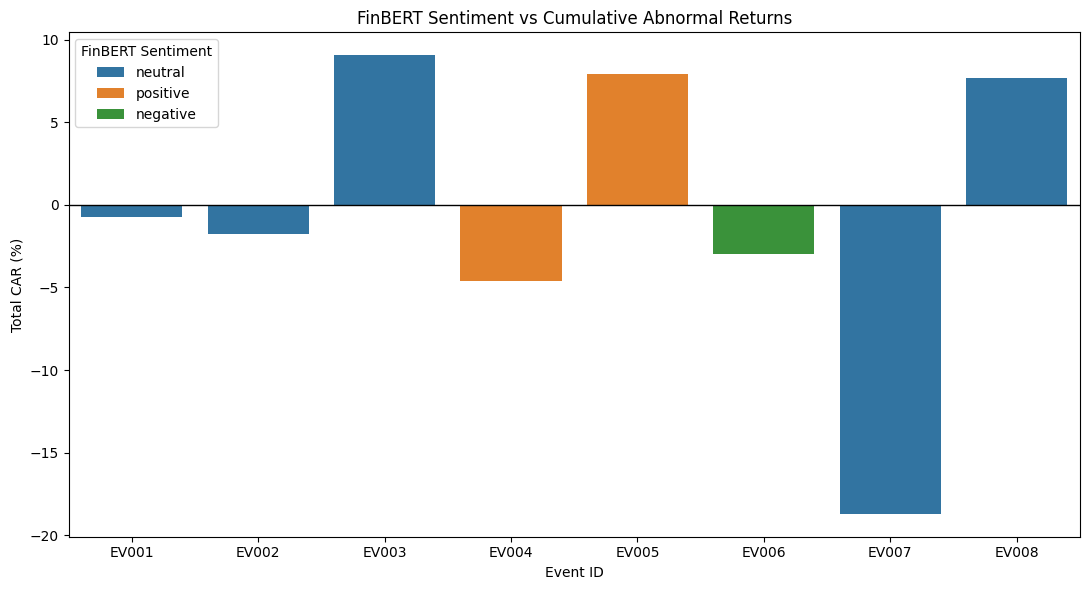

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(11, 6))

sns.barplot(
    data=integrated_event_data,
    x="event_id",
    y="total_CAR",
    hue="FinBERT_Sentiment",
    dodge=False
)

plt.axhline(0, color="black", linewidth=1)
plt.title("FinBERT Sentiment vs Cumulative Abnormal Returns")
plt.xlabel("Event ID")
plt.ylabel("Total CAR (%)")
plt.legend(title="FinBERT Sentiment")
plt.tight_layout()
plt.show()

In [14]:
from scipy.stats import spearmanr

# Variables for correlation analysis
correlation_variables = [
    "Positive_Probability",
    "Negative_Probability",
    "Neutral_Probability",
    "Sentiment_Entropy",
    "total_CAR"
]

# Calculate Spearman correlation matrix
spearman_matrix = integrated_event_data[
    correlation_variables
].corr(method="spearman")

print("Spearman Correlation Matrix:")
display(spearman_matrix)

# Calculate individual correlations with CAR
print("\nCorrelation with Total CAR:")

for column in correlation_variables[:-1]:
    corr, p_value = spearmanr(
        integrated_event_data[column],
        integrated_event_data["total_CAR"]
    )

    print(
        f"{column}: Correlation = {corr:.4f}, "
        f"P-value = {p_value:.4f}"
    )

Spearman Correlation Matrix:


,Positive_Probability,Negative_Probability,Neutral_Probability,Sentiment_Entropy,total_CAR
Positive_Probability,1.000000,0.642857,-0.833333,0.880952,0.190476
Negative_Probability,0.642857,1.000000,-0.904762,0.857143,-0.119048
Neutral_Probability,-0.833333,-0.904762,1.000000,-0.904762,-0.071429
Sentiment_Entropy,0.880952,0.857143,-0.904762,1.000000,0.023810
total_CAR,0.190476,-0.119048,-0.071429,0.023810,1.000000



Correlation with Total CAR:
Positive_Probability: Correlation = 0.1905, P-value = 0.6514
Negative_Probability: Correlation = -0.1190, P-value = 0.7789
Neutral_Probability: Correlation = -0.0714, P-value = 0.8665
Sentiment_Entropy: Correlation = 0.0238, P-value = 0.9554


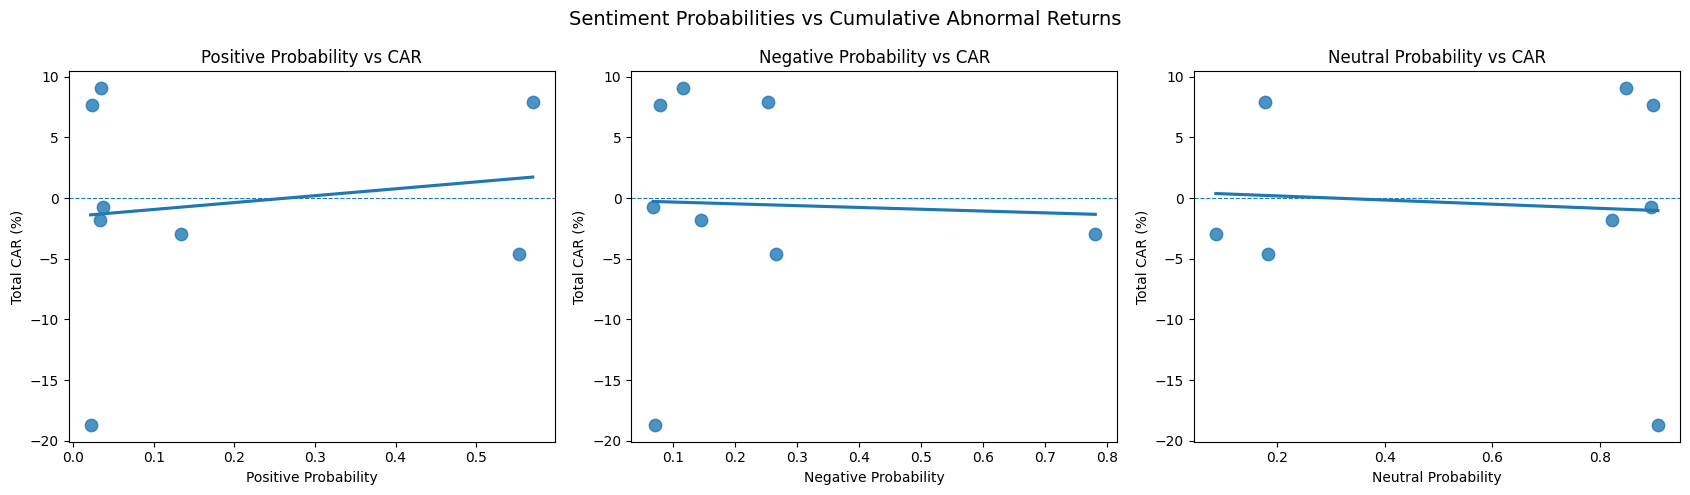

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

features = [
    ("Positive_Probability", "Positive Probability"),
    ("Negative_Probability", "Negative Probability"),
    ("Neutral_Probability", "Neutral Probability")
]

for ax, (column, label) in zip(axes, features):

    sns.regplot(
        data=integrated_event_data,
        x=column,
        y="total_CAR",
        ax=ax,
        ci=None,
        scatter_kws={"s": 80}
    )

    ax.set_title(f"{label} vs CAR")
    ax.set_xlabel(label)
    ax.set_ylabel("Total CAR (%)")
    ax.axhline(0, linestyle="--", linewidth=0.8)

plt.suptitle(
    "Sentiment Probabilities vs Cumulative Abnormal Returns",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [16]:
company_comparison = (
    integrated_event_data
    .groupby("company")
    .agg(
        Event_Count=("event_id", "count"),
        Average_CAR=("total_CAR", "mean"),
        Average_Positive_Probability=("Positive_Probability", "mean"),
        Average_Negative_Probability=("Negative_Probability", "mean"),
        Average_Neutral_Probability=("Neutral_Probability", "mean"),
        Average_Entropy=("Sentiment_Entropy", "mean")
    )
    .reset_index()
)

print("Company-wise Sentiment and CAR Comparison:")
display(company_comparison.round(4))

Company-wise Sentiment and CAR Comparison:


,company,Event_Count,Average_CAR,Average_Positive_Probability,Average_Negative_Probability,Average_Neutral_Probability,Average_Entropy
0,AAPL,3,2.1777,0.0348,0.1095,0.8557,0.4434
1,MSFT,3,0.1240,0.4188,0.4331,0.1481,0.8000
2,TSLA,2,-5.4998,0.0221,0.0747,0.9032,0.3367


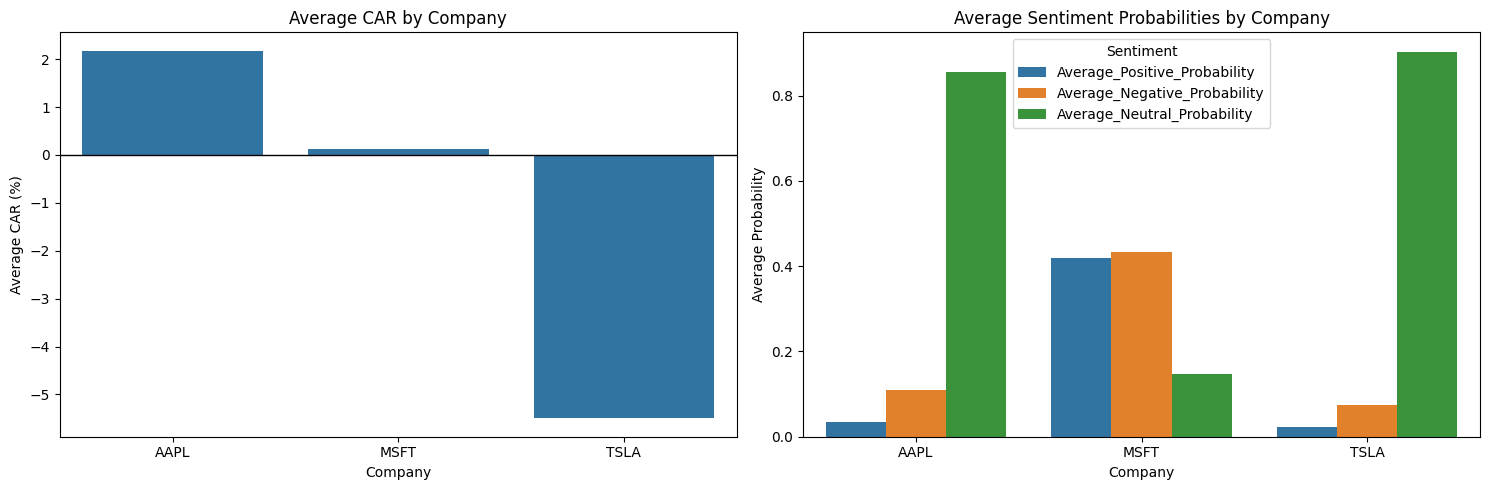

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Chart 1: Average CAR by company
sns.barplot(
    data=company_comparison,
    x="company",
    y="Average_CAR",
    ax=axes[0]
)

axes[0].axhline(0, color="black", linewidth=1)
axes[0].set_title("Average CAR by Company")
axes[0].set_xlabel("Company")
axes[0].set_ylabel("Average CAR (%)")

# Chart 2: Average sentiment probabilities
sentiment_columns = [
    "Average_Positive_Probability",
    "Average_Negative_Probability",
    "Average_Neutral_Probability"
]

company_sentiment = company_comparison[
    ["company"] + sentiment_columns
].melt(
    id_vars="company",
    var_name="Sentiment",
    value_name="Probability"
)

sns.barplot(
    data=company_sentiment,
    x="company",
    y="Probability",
    hue="Sentiment",
    ax=axes[1]
)

axes[1].set_title("Average Sentiment Probabilities by Company")
axes[1].set_xlabel("Company")
axes[1].set_ylabel("Average Probability")
axes[1].legend(title="Sentiment")

plt.tight_layout()
plt.show()

In [18]:
# Final validation
print("FINAL VALIDATION - NOTEBOOK 04")
print("-" * 45)

# 1. Check number of events
print("Total events:", len(integrated_event_data))

# 2. Check unique event IDs
print("Unique event IDs:", integrated_event_data["event_id"].nunique())

# 3. Check missing values
print("Total missing values:", integrated_event_data.isnull().sum().sum())

# 4. Check duplicate events
print("Duplicate event IDs:", integrated_event_data["event_id"].duplicated().sum())

# 5. Check probability sums
probability_sum = integrated_event_data[
    ["Positive_Probability", "Negative_Probability", "Neutral_Probability"]
].sum(axis=1)

print("All probability sums equal 1:",
      np.allclose(probability_sum, 1.0))

# 6. Check CAR values
print("CAR values available:",
      integrated_event_data["total_CAR"].notna().all())

# 7. Check company comparison
print("Companies analysed:", company_comparison["company"].nunique())

# Save final outputs
integrated_event_data.to_csv(
    RESULTS_DIR / "integrated_event_sentiment_car.csv",
    index=False
)

company_comparison.to_csv(
    RESULTS_DIR / "company_sentiment_car_comparison.csv",
    index=False
)

event_news_mapping.to_csv(
    RESULTS_DIR / "final_event_news_mapping.csv",
    index=False
)

print("\nFinal output files saved successfully.")

FINAL VALIDATION - NOTEBOOK 04
---------------------------------------------
Total events: 8
Unique event IDs: 8
Total missing values: 0
Duplicate event IDs: 0
All probability sums equal 1: True
CAR values available: True
Companies analysed: 3

Final output files saved successfully.


## Conclusion

This notebook integrated FinBERT-based sentiment analysis with quantitative event study results for eight verified earnings announcements from Apple, Microsoft, and Tesla.

The announcement titles were analysed using FinBERT to obtain positive, negative, and neutral sentiment probabilities. Sentiment entropy was also calculated to understand the uncertainty in the model's predictions.

These sentiment features were then integrated with cumulative abnormal returns (CAR) obtained from the quantitative event study.

### Key Findings

1. FinBERT classified five announcement titles as neutral, two as positive, and one as negative.
2. Two of the three non-neutral sentiment predictions were directionally aligned with CAR, while one showed disagreement.
3. Spearman correlation analysis showed very weak associations between sentiment probabilities and CAR.
4. Company-wise comparison showed different sentiment distributions and average CAR values across Apple, Microsoft, and Tesla.
5. Some announcement titles received neutral sentiment predictions despite substantial positive or negative market reactions.

### Limitations

- The analysis contains only eight earnings events from three companies.
- FinBERT analysed short official announcement titles rather than complete financial news articles or earnings releases.
- Sentiment predictions are model-generated outputs and have not been independently validated against human-labelled financial sentiment.
- Announcement titles may not represent actual financial performance or investor expectations.
- The small sample size limits the reliability and statistical power of correlation analysis.
- CAR represents abnormal stock-price movement relative to the selected market model; it does not establish causality or represent a directly executable trading return.
- Other market announcements and external factors may have influenced stock-price movements.

### Overall Conclusion

The integrated analysis demonstrates a workflow for combining NLP-based financial sentiment features with quantitative event study measurements.

However, the current pilot results do not establish a reliable predictive relationship between announcement-title sentiment and cumulative abnormal returns. A larger dataset containing full news articles, independently verified events, and more companies is required for stronger conclusions and predictive modelling.

### Future Improvements

- Collect a larger dataset of verified financial news and earnings announcements.
- Analyse complete news articles instead of announcement titles alone.
- Validate sentiment predictions using manually labelled financial news.
- Include more companies, sectors, and market conditions.
- Investigate the relationship between sentiment, CAR, and trading volume.
- Evaluate predictive performance using chronological train-test splits and out-of-sample testing.